In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
df = pd.read_csv('/Users/pawn/Desktop/NTI/cars_data.csv')

In [45]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [46]:
df.shape

(1000, 8)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   object 
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   object 
 5   Transmission     1000 non-null   object 
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 62.6+ KB


In [48]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,1000.000000,1000.000000,980.000000,1000.000000,1000.000000
mean,2016.300000,104551.675000,2.494592,3.062000,8473.646000
std,4.056162,56197.795061,0.865230,1.404325,6292.910864
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4069.500000
50%,2016.000000,105298.000000,2.500000,3.000000,6439.000000
75%,2020.000000,155468.250000,3.225000,4.000000,10905.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [49]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

In [50]:
df.drop(['Previous_Owners'] , axis= 1 , inplace=True)

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df.reset_index(drop=True , inplace= True)

In [53]:
df.isnull().sum().sort_values(ascending=False)


Engine_Size     20
Brand            0
Year             0
Mileage          0
Fuel_Type        0
Transmission     0
Price            0
dtype: int64

In [54]:
df.isnull().sum()

Brand            0
Year             0
Mileage          0
Engine_Size     20
Fuel_Type        0
Transmission     0
Price            0
dtype: int64

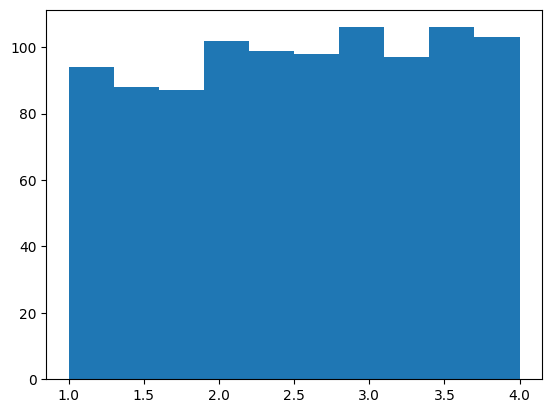

In [55]:
plt.hist(df['Engine_Size'])
plt.show()

In [56]:
df['Engine_Size'].skew()

np.float64(-0.03026370130475467)

In [57]:
from sklearn.impute import SimpleImputer


In [58]:
impute = SimpleImputer(strategy='mean')
impute.fit(df[['Engine_Size']])
df[['Engine_Size']] = impute.transform(df[['Engine_Size']])

In [59]:
df.isnull().sum().sum()

np.int64(0)

In [60]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Price
0,Kia,2015,110373,2.5,Electric,Manual,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,3000
4,BMW,2014,148748,3.5,Diesel,Manual,6451


<Axes: xlabel='Year', ylabel='Mileage'>

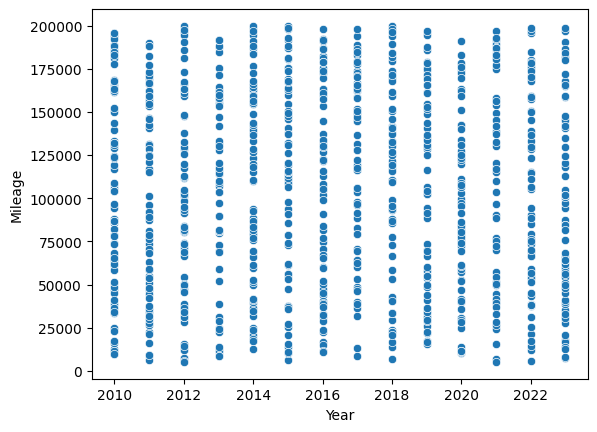

In [61]:
sns.scatterplot(data=df,x='Year',y='Mileage')

<Axes: xlabel='Price', ylabel='Brand'>

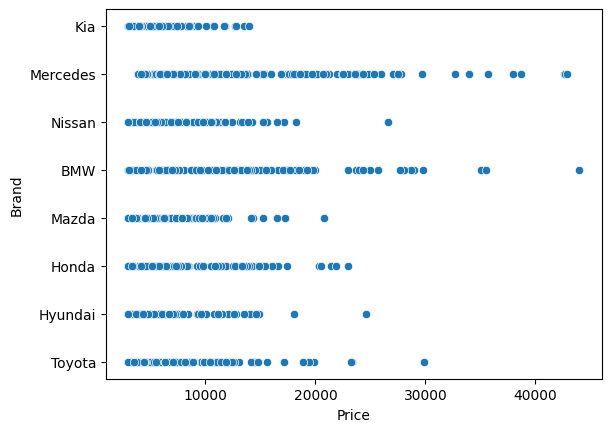

In [62]:
sns.scatterplot(data=df,x='Price',y='Brand')

<Axes: xlabel='Year', ylabel='Price'>

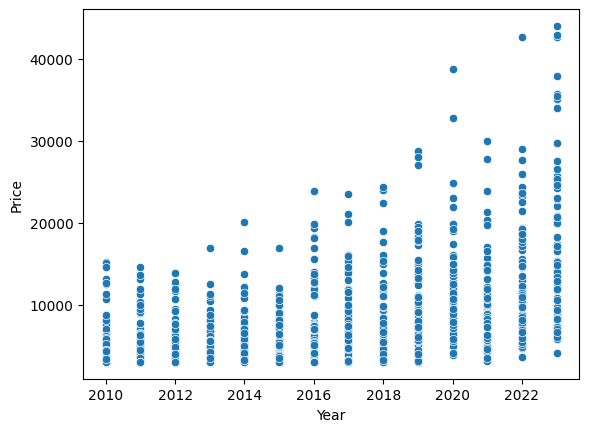

In [63]:
sns.scatterplot(data=df,x='Year',y='Price')

<Axes: xlabel='Fuel_Type', ylabel='Price'>

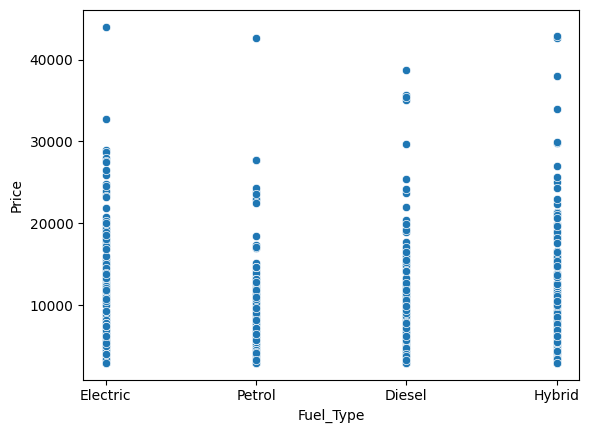

In [64]:
sns.scatterplot(data=df,x='Fuel_Type',y='Price')

In [65]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Price
0,Kia,2015,110373,2.5,Electric,Manual,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,3000
4,BMW,2014,148748,3.5,Diesel,Manual,6451


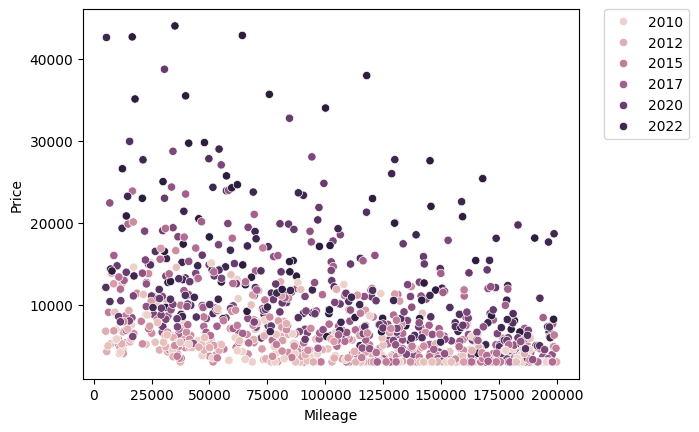

In [66]:
sns.scatterplot(data=df,y='Price',x='Mileage',hue='Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

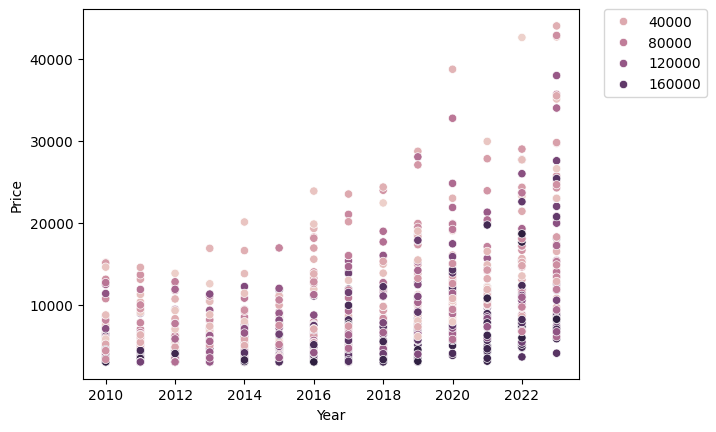

In [67]:
sns.scatterplot(data=df,y='Price',x='Year',hue='Mileage')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

In [68]:
from sklearn.preprocessing import LabelBinarizer


In [69]:
lb = LabelBinarizer()

In [70]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [71]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

Brand number unique:  8
--------------------------------------------------
Fuel_Type number unique:  4
--------------------------------------------------
Transmission number unique:  2
--------------------------------------------------


In [72]:
for col in ['Transmission']:
    df[col] = lb.fit_transform(df[col])

In [73]:
for col in ['Fuel_Type']:
    df[col] = le.fit_transform(df[col])

In [74]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

Brand number unique:  8
--------------------------------------------------


In [75]:
from sklearn.preprocessing import OneHotEncoder

In [76]:
onhot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [77]:
temp = onhot.fit_transform(df[['Brand']])
df = pd.concat([df,temp],axis=1)

In [78]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

Brand number unique:  8
--------------------------------------------------


In [79]:
df.drop(['Brand'] , axis = 1 , inplace=True )

In [80]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

In [81]:
from sklearn.model_selection import train_test_split

In [82]:
X = df.drop('Price',axis = 1)
y = df['Price']

In [83]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [84]:
import category_encoders as ce